# 10. Vanilla MRAC + linear damper in Guha-Annaswamy notation

**EXPLORATORY / offline / PROXY.** Reduced taut Newton-Euler model (`QuadLoadPend`), development PC. A real (mismatched) vehicle with a payload follows a *nominal* vehicle with a nominal payload (4 kg / 2 m). The nominal vehicle is flown by the baseline PID+FF (PID control plus payload feedforward) plus the linear swing damper. In this offline model that damper stays in the reference; what is planned about a residual policy is stated under **Next** in Section 9.

The law has an exact Lyapunov guarantee **on its stated model**: the linearized outer model, matched case, continuous time. The nonlinear sampled loop is validated numerically. **No stability claim is made for it.**

**Terms used in this notebook** (the full glossary is `00_Notation_and_Reading_Guide.ipynb`).
- **MQP** is the thesis derivation note *MRAC for a planar quadrotor with a cable-suspended payload* (`.ai/research/derivations/mrac-quadrotor-payload.md` in the thesis repository). Its status is PROPOSED, not accepted. Sections are cited as "MQP §x (section name)". This notebook carries the key steps itself, so you do not need to open the note.
- **EQ-MR-22** is the registry ID of the vanilla MRAC law in the thesis equation registry (`.ai/research/equation-registry.md`). The wave of work that built and validated it is called W2e (the vanilla Guha-Annaswamy MRAC wave).
- **Guha-Annaswamy notation:** the symbols of Guha and Annaswamy's MRAC-RL paper ($x$, $x_r$, $A$, $B_r\Lambda$, $\xi$, $\hat K$, $\Gamma$, $P$, $Q$), used so that the formulas can be compared with the paper line by line.

| Source | Where |
|---|---|
| Derivation | MQP §6.14, "Vanilla state-space MRAC in Guha-Annaswamy notation" (`.ai/research/derivations/mrac-quadrotor-payload.md`), registry EQ-MR-22 |
| Code | `experiments/mrac/vanilla_mrac.py`; runner `mrac_lab/vanilla_runs.py` |
| Tests | `tests/mrac/test_vanilla_mrac.py`; symbolic check `check_vanilla.py` (local) |
| Architecture and v2 reconciliation | `.ai/architecture/mrac-rl-plan/17_vanilla_mrac_guha.md` (design note; it also relates this law to Javier's MRAC-RL integration plan, version 2) |
| Paper | Guha and Annaswamy, MRAC-RL (arXiv 2011.10562), eqs. 4-6, Thm. 1-2 |

Running all cells reads saved results and evaluates closed-form quantities. It runs no episodes, tuning or training.

**Coordinate scope.** The derivations below use residual.tex order at $d=0$. Numerical tables and plots are generated in **code coordinates**; their values are not transformed. Code returns $x_{code}=(y_q,v_{q,y},\phi_{code},\dot\phi_{code},z_q,v_{q,z})$, while the derivations use $x_o=(y_q,v_{q,y},z_q,v_{q,z},\varphi,\dot\varphi)^T=T x_{code}$, with $T=S\Pi$, $\Pi$ permuting entries $(0,1,4,5,2,3)$ and $S=\mathrm{diag}(1,1,1,1,-1,-1)$.

**Cable offset.** The derivations are at $d=0$ (cable attached at the vehicle centre of mass). The hover check of Section 5 and the episodes of Sections 7 and 8 use the canonical offline vehicle, whose cable attaches $d=0.3795$ m below the centre of mass (protocol 03). There the offset coupling is one more residual outside the proof (MQP premise V2, Section 2).


### Notation used across this series (added 2026-11-25)

The thesis notation (`thesis_book/residual.tex`, lines 95-292) is primary. The code and MQP (the derivation note defined in the header) use their own symbols, mapped in the thesis file `.ai/research/derivations/notation-residual-tex.md`. `00_Notation_and_Reading_Guide.ipynb` explains the map with a worked example.

| This notebook / code | residual.tex | Note |
|---|---|---|
| `m_L`, `l` | $m_b$, $\ell$ | payload mass, rope length |
| `m_q`, `J`; `f`, `tau` | $m_q$, $J_q$; $f_q$, $\tau_q$ | |
| `phi` (code) | $\varphi$ | **$\varphi_{\rm tex} = -\varphi_{\rm code}$** with the cable at the vehicle CoG ($d = 0$). Odd functions of $\varphi$ flip sign; $\cos\varphi$, the tension and the tangent do not. With an offset $d\ne0$ the map is nonlinear |
| task reference `p_r(t)` | $x^d$ ("reference state" in residual.tex) | not Guha's reference model $x_r$ |

Numbers in this notebook are unchanged; only the reading of the symbols is aligned.

*Cached runs:* this notebook reads local run folders `results/mrac_*`, which are not in Git. On a fresh clone the first cell that needs one stops with a message naming `RESULTS_REGEN.md`, which lists the command that produced each folder; only folders whose receipt says `completed` are used.

In [1]:
import json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mrac_lab import provenance

prov = provenance.setup(modules=("experiments.mrac.vanilla_mrac", "experiments.mrac.quad_load_pend"))
provenance.banner(prov, "Vanilla MRAC (EQ-MR-22)", notes=(
    "Exact result only for the continuous linear outer model with l = l_r.",
    "Inner loop, motor lag, d-coupling, ZOH, saturation and cable-length mismatch are residuals.",
))
from experiments.mrac.baselines import canonical_offline_params
from experiments.mrac.vanilla_mrac import (VanillaDesign, VanillaParams, outer_model, ideal_gains,
                                           baseline_error_gains, hover_tick_jacobian)
canon = canonical_offline_params()
RES = Path("results")
from mrac_lab import results as _results

def latest(stage):
    """Newest completed run folder of a stage (receipt status checked; aborted runs are skipped)."""
    return _results.latest_completed(f"mrac_vanilla_{stage}", results=RES, prefer_composite=False)

Vanilla MRAC (EQ-MR-22)
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: <thesis> (machine path redacted 2026-11-27)
Commit: 4cfea8a665fe1baa8ffdf1e53e80b5a0cee0edef (branch Claude, clean for experiments/mrac, experiments/notebook_utils/style.py, gym_pymunk_quadrotor)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.vanilla_mrac -> <thesis>/experiments/mrac/vanilla_mrac.py
import origin: experiments.mrac.quad_load_pend -> <thesis>/experiments/mrac/quad_load_pend.py
Note: Exact result only for the continuous linear outer model with l = l_r.
Note: Inner loop, motor lag, d-coupling, ZOH, saturation and cable-length mismatch are residuals.


## 1. Notation (residual.tex ↔ this notebook ↔ code)

| residual.tex | Meaning | Code |
|---|---|---|
| $x_o=(y_q,v_{q,y},z_q,v_{q,z},\varphi,\dot\varphi)$ | six-state outer vector, residual.tex order | $T x_{code}$ |
| $x_{code}=(y_q,v_{q,y},\phi_{code},\dot\phi_{code},z_q,v_{q,z})$ | order returned by the implementation | `outer_state` |
| $x_r$ | same residual.tex coordinates of the nominal reference vehicle | reference-model state |
| $A,\ B=B_r\Lambda$ | real and reference state-space matrices, $\Lambda=\mathrm{diag}(m_{q,r}/m_q,M_r/M)>0$ | `outer_model` |
| $u_r$ | policy on the reference: PID+FF plus softer damper | `NominalReference` |
| $K_e^T e$ | error feedback making $A_H=A_r-B_rK_e^T$ Hurwitz | `baseline_error_gains` |
| $\xi$ | $\nu_r-K_e^Te$ | reference gravity-offset input minus error feedback |
| $\hat K_x,\hat K_u$ | gains on $\bar x_o=(x_o,1)$ and on $\xi$ | adaptive gains |
| $\Gamma_x,\Gamma_u$ | elementwise positive adaptation gains | update gains |

For matrices, use $A_{tex}=T A_{code}T^T$, $B_{tex}=T B_{code}$, $K_{e,tex}=T K_{e,code}$ and $K_{x,tex}=\mathrm{diag}(T,1)K_{x,code}$; the two input columns and $K_u$ are unchanged. The simple angle sign flip and these tutorial derivations are scoped to $d=0$.

**Dimensions** (stated once, used below). $x_o,x_r,e\in\mathbb R^6$; $F=(F_y,F_z)^\top\in\mathbb R^2$; $A,A_r,A_H\in\mathbb R^{6\times6}$; $B,B_r\in\mathbb R^{6\times2}$; $\Lambda\in\mathbb R^{2\times2}$ diagonal; $\bar x_o\in\mathbb R^{7}$; $\hat K_x,K_x^*,\Gamma_x\in\mathbb R^{7\times2}$; $\hat K_u,K_u^*,\Gamma_u\in\mathbb R^{2\times2}$; $\xi\in\mathbb R^{2}$; $K_e\in\mathbb R^{6\times2}$; $P,Q\in\mathbb R^{6\times6}$ symmetric positive definite. The columns of $B$ and $B_r$ correspond to the inputs $F_y$ and $F_z$.

## 1b. The idea, and what this notebook derives

**The idea.** A *nominal* vehicle (9.6 kg, 4 kg payload, 2 m rope) is simulated alongside the real vehicle, whose masses may be wrong. Both are driven by the baseline PID+FF plus the linear swing damper. The real vehicle receives the baseline command corrected by an *adaptive gain layer*: the force sent to the real plant is one gain times the corrected nominal command $\xi$, plus gains times the state, plus a constant. The gains start at their nominal values. They are updated by laws chosen so that a Lyapunov function (a non-negative "energy" of the tracking error and of the gain errors) cannot grow. If the mismatch is of the kind the gains can absorb (the *matched* case: payload and vehicle mass), the tracking error between the real and the nominal vehicle goes to zero in the continuous-time linear matched model with bounded reference signals (section 4); the sampled nonlinear loop is not covered by that result.

**Where each step is derived.**

| Section | Question | Source |
|---|---|---|
| 2 | What linear model does the law act on, and when can gains exist that make the plant look like the reference ("matching")? | MQP §6.14.2 (outer model), §6.14.3 (matching conditions) |
| 3 | What is the reference, the error $e$, and the error feedback $K_e$? Where do the damper gain and the eigenvalues of $A_H$ come from (3.1, 3.2)? | MQP §6.14.4 (reference model, error feedback and the swing error) |
| 4 | What is the law, why does the Lyapunov derivative reduce to $-e^\top Qe$, and what does σ-modification add? | MQP §6.14.5 (law and updates), §6.14.6 (Lyapunov result) |
| 5-6 | Why check the sampled implementation, and why did the older A0 law not converge? | MQP §6.14.8 (pre-tuning check), `02_convergence_analysis.md` (local, untracked) |
| 7-8 | What do the numerical validation and tuning show? | saved results |

**Prerequisites.** NB02 (the scalar Lyapunov argument), NB03 (matrix trace identities for the MIMO case), NB04 (Guha and Annaswamy's setting), NB05 (the taut point-load model) and NB06 (the baseline PID+FF and linear damper). Every step is repeated below in the form it is used here.

## 2. Outer model and matching

> **Where this comes from.**
> - **Source:** MQP §6.14.2 (outer model: taut hover, z-up, world-force input) and §6.14.3 (matching conditions). MQP is written in code angles; here the same equations are given in residual.tex angle signs (`.ai/research/derivations/notation-residual-tex.md` §8.1-8.2).
> - **Prerequisites:** NB05 (the exact taut point-load model: Newton-Euler for vehicle and payload); NB04 (the plant pair $(A,B)$ and the reference pair $(A_r,B_r)$).
> - **Assumptions:**
>   1. The rope is taut, massless and inextensible, with length $\ell$. The payload is a point mass $m_b$ attached at the vehicle centre of mass ($d=0$).
>   2. Ideal inner loop (MQP premise V1): the attitude loop realizes the requested world force $F=(F_y,F_z)^\top$ exactly.
>   3. The coupling of the attachment offset with the vehicle attitude acceleration is dropped (MQP premise V2). It is zero at $d=0$ in any case.
>   4. Small swing about hover: $\sin\varphi\approx\varphi$, $\cos\varphi\approx1$, and products of small quantities are dropped.

### 2.1 Where the linear model comes from

Start from the exact taut model of NB05, at $d=0$, in residual.tex signs. Let $\hat q=[-\sin\varphi,\,-\cos\varphi]^\top$ be the unit vector from vehicle to load, $T\ge0$ the tension and $e_2$ the vertical unit vector:
$$m_q\ddot r_q=F-m_qg\,e_2+T\hat q,\qquad m_b\ddot r_b=-T\hat q-m_bg\,e_2,\qquad r_b=r_q+\ell\hat q.\tag{E}$$
At hover $\varphi=0$ and the payload hangs below the vehicle, so $T=m_bg$. The three scalar equations follow by linearizing (E):

1. **Lateral, vehicle.** The $e_1$ component of the vehicle equation has $\hat q_y=-\sin\varphi\approx-\varphi$. A tension change $\delta T$ multiplies $\varphi$, which is second order, so $T\approx m_bg$:
$$m_q\ddot y_q=F_y-m_bg\,\varphi.\tag{1}$$
2. **Lateral, load.** The load position is $y_b=y_q-\ell\sin\varphi\approx y_q-\ell\varphi$, so $\ddot y_b\approx\ddot y_q-\ell\ddot\varphi$. The $e_1$ component of the load equation is $m_b\ddot y_b=-T\hat q_y=T\sin\varphi\approx m_bg\varphi$. Substituting $\ddot y_b$ and cancelling $m_b$:
$$\ell\ddot\varphi=\ddot y_q-g\varphi.\tag{2}$$
3. **Vertical.** The vehicle equation has $+T\hat q_z=-T\cos\varphi$ and the load equation has $-T\hat q_z=+T\cos\varphi$. Adding the two vertical equations cancels the tension exactly: $m_q\ddot z_q+m_b\ddot z_b=F_z-(m_q+m_b)g$. Since $z_b=z_q-\ell\cos\varphi\approx z_q-\ell+\ell\varphi^2/2$, to first order $\ddot z_b=\ddot z_q$, so
$$M\ddot z_q=F_z-Mg,\qquad M=m_q+m_b.\tag{3}$$

Eliminate $\ddot y_q$ from (2) with (1): $\ddot\varphi=\dfrac{F_y}{m_q\ell}-\dfrac{g}{\ell}\Big(1+\dfrac{m_b}{m_q}\Big)\varphi$. Now read off the rows of $\dot x_o=Ax_o+B(F-Mg\,e_2)$ for $x_o=(y_q,v_{q,y},z_q,v_{q,z},\varphi,\dot\varphi)^\top$:

| Row | Equation | Entries |
|---|---|---|
| 1 | $\dot y_q=v_{q,y}$ | $A_{12}=1$ |
| 2 | $\dot v_{q,y}=-\frac{m_bg}{m_q}\varphi+\frac1{m_q}F_y$ | $A_{25}=-\frac{m_bg}{m_q}$, $B_{21}=\frac1{m_q}$ |
| 3 | $\dot z_q=v_{q,z}$ | $A_{34}=1$ |
| 4 | $\dot v_{q,z}=\frac1M(F_z-Mg)$ | $B_{42}=\frac1M$ |
| 5 | $\dot\varphi=\dot\varphi$ | $A_{56}=1$ |
| 6 | $\ddot\varphi=\dots$ above | $A_{65}=-\frac g\ell\big(1+\frac{m_b}{m_q}\big)$, $B_{61}=\frac1{m_q\ell}$ |

These are the nonzero entries:

$$A_{12}=A_{34}=A_{56}=1,\quad A_{25}=-\frac{m_b g}{m_q},\quad A_{65}=-\frac{g}{\ell}\left(1+\frac{m_b}{m_q}\right),\qquad B_{21}=\frac1{m_q},\quad B_{42}=\frac1M,\quad B_{61}=\frac1{m_q\ell}.$$

Here $B$ is a state-space input matrix, not the motor-allocation matrix. The equations use residual.tex angle signs; the code angle is $\phi_{code}=-\varphi$ only for $d=0$.

**Intuition.** A payload on a rope behaves like a pendulum hanging from the vehicle. The cable pull acts on the vehicle like a spring toward the payload: a swing angle $\varphi$ drags the vehicle sideways with a force of about $m_bg$ per radian. Vertically the vehicle simply carries the total weight $Mg$, because the tension cancels between the two bodies.

### 2.2 Matching conditions, line by line

**Goal.** The reference model has the same structure with parameters $(m_{q,r},m_{b,r},\ell_r)$ and $M_r=m_{q,r}+m_{b,r}$. We look for a positive diagonal $\Lambda$ and gains $K_x^*,K_u^*$ with
$$B=B_r\Lambda,\qquad A_r-A=B_r\Lambda K_x^{*\top},\qquad K_u^*=\Lambda^{-1}.$$
These are exactly the *matching conditions*: the plant differs from the reference only through the input columns being rescaled ($\Lambda$) and through a state-feedback term the input can produce ($B_r\Lambda K_x^{*\top}$).

**Step 1: input matrix.** Write the two columns of $B$ (inputs $F_y$, $F_z$):
$$B_{[:,1]}=\Big(0,\tfrac1{m_q},0,0,0,\tfrac1{m_q\ell}\Big)^\top,\qquad B_{[:,2]}=\Big(0,0,0,\tfrac1M,0,0\Big)^\top,$$
and the same with the subscript $r$ for $B_r$. For $\ell=\ell_r$, $B_{[:,1]}=\frac{m_{q,r}}{m_q}B_{r[:,1]}$ (both nonzero entries scale by $m_{q,r}/m_q$) and $B_{[:,2]}=\frac{M_r}{M}B_{r[:,2]}$. Multiplying $B_r$ by a diagonal $\Lambda$ scales its columns, so $B=B_r\Lambda$ with $\Lambda=\mathrm{diag}(m_{q,r}/m_q,\,M_r/M)>0$.

**Step 2: $A_r-A$ column by column.** $A$ and $A_r$ share all structural ones ($A_{12},A_{34},A_{56}$). They differ only in $A_{25}$ and $A_{65}$, both in column 5 (the $\varphi$ column). Put $\mu=m_b/m_q$ and $\mu_r=m_{b,r}/m_{q,r}$:
$$(A_r-A)_{25}=-g\mu_r+g\mu=g(\mu-\mu_r),\qquad (A_r-A)_{65}=-\frac g{\ell_r}(1+\mu_r)+\frac g\ell(1+\mu)\overset{\ell=\ell_r}{=}\frac g\ell(\mu-\mu_r).$$
So for $\ell=\ell_r$ every column of $A_r-A$ is zero except column 5, which is
$$g(\mu-\mu_r)\,\big(0,\,1,\,0,\,0,\,0,\,\tfrac1\ell\big)^\top .$$
Its entries in rows 2 and 6 are in the ratio $1:1/\ell$, which is exactly the ratio of the two nonzero entries of $B_{r[:,1]}$. That is why this column can be produced by the $F_y$ input.

**Step 3: solve for $K_x^*$ entry by entry.** Column 5 of $B_r\Lambda K_x^{*\top}$ is $B_r\Lambda\,k_\varphi$ with $k_\varphi=(K_x^*[\varphi,F_y],K_x^*[\varphi,F_z])^\top$. Writing out the two terms:
$$B_r\Lambda k_\varphi=\underbrace{\Big(0,\tfrac1{m_{q,r}},0,0,0,\tfrac1{m_{q,r}\ell}\Big)^\top\tfrac{m_{q,r}}{m_q}K_x^*[\varphi,F_y]}_{\text{input }F_y}+\underbrace{\Big(0,0,0,\tfrac1{M_r},0,0\Big)^\top\tfrac{M_r}{M}K_x^*[\varphi,F_z]}_{\text{input }F_z}=\Big(0,\tfrac{K_x^*[\varphi,F_y]}{m_q},0,\tfrac{K_x^*[\varphi,F_z]}{M},0,\tfrac{K_x^*[\varphi,F_y]}{m_q\ell}\Big)^\top .$$
Equate with the column of Step 2:
- Row 2: $K_x^*[\varphi,F_y]/m_q=g(\mu-\mu_r)$, so $K_x^*[\varphi,F_y]=g(m_b-m_q\mu_r)=g\Big(m_b-\dfrac{m_qm_{b,r}}{m_{q,r}}\Big)$.
- Row 6: $K_x^*[\varphi,F_y]/(m_q\ell)=g(\mu-\mu_r)/\ell$. This is the same equation, so the system is consistent.
- Row 4: $K_x^*[\varphi,F_z]=0$.
- Every other column of $A_r-A$ is zero. Since $B_r\Lambda$ has full column rank, $B_r\Lambda k=0$ forces $k=0$, so every other state row of $K_x^*$ vanishes.

*Direct check in row 2.* Give the plant the force $F_y=\frac{m_q}{m_{q,r}}\xi_y+K_x^*[\varphi,F_y]\varphi$. Then $\dot v_{q,y}=\frac{\xi_y}{m_{q,r}}+\frac{K_x^*[\varphi,F_y]-m_bg}{m_q}\varphi$, and the reference has $\dot v_{q,y,r}=\frac{\xi_y}{m_{q,r}}-\frac{m_{b,r}g}{m_{q,r}}\varphi$. They agree when $K_x^*[\varphi,F_y]=m_bg-m_q\frac{m_{b,r}g}{m_{q,r}}$, the same value.

**Step 4: the constant entry (gravity).** $\bar x_o=(x_o,1)$ carries a constant regressor. The plant input is $F-Mg\,e_2$ and the reference input is $\nu_r$ (gravity already removed), so the ideal force must contain $Mg\,e_2$ to cancel the plant's own weight. Hence the constant row of $K_x^*$ is $(0,\,Mg)$, that is $K_x^*[1,F_y]=0$, $K_x^*[1,F_z]=Mg$.

**Step 5: $K_u^*$.** The $\xi$ term must satisfy $B_r\Lambda K_u^{*\top}\xi=B_r\xi$, so $K_u^{*\top}=\Lambda^{-1}$, and since $\Lambda$ is diagonal $K_u^*=\Lambda^{-1}$.

**Result.** The ideal gains satisfy
$$A_r-A=B_r\Lambda K_x^{*T},\qquad K_u^*=\Lambda^{-1},$$
with nonzero entries
$$K_x^*[\varphi,F_y]=g\left(m_b-\frac{m_qm_{b,r}}{m_{q,r}}\right),\qquad K_x^*[1,F_z]=Mg.$$

The $K_x^*[\varphi,F_y]$ entry is a horizontal-force coefficient in N/rad (with radians dimensionless); $K_x^*[1,F_z]=Mg$ is a force coefficient in N. The first gain is expressed in residual.tex angle convention and is the negative of the code-angle entry. Payload/vehicle mass mismatch is matched; cable-length mismatch is not, because for $\ell\ne\ell_r$ no ideal matching gains exist.

**Why $\ell\ne\ell_r$ breaks matching.** Two things fail. (i) $B_{[:,1]}\propto(0,1,0,0,0,1/\ell)^\top$ is no longer parallel to $B_{r[:,1]}\propto(0,1,0,0,0,1/\ell_r)^\top$, so no $\Lambda$ gives $B=B_r\Lambda$. (ii) Column 5 of $A_r-A$ has row 2 equal to $g(\mu-\mu_r)$ and row 6 equal to $-\frac g{\ell_r}(1+\mu_r)+\frac g\ell(1+\mu)$. Its distance from the range of $B_r$ (rows 2 and 6 in the ratio $1:1/\ell_r$) is
$$\text{row 6}-\frac{\text{row 2}}{\ell_r}=g(1+\mu)\Big(\frac1\ell-\frac1{\ell_r}\Big)\neq0 .$$
Physically, the swing frequency depends on $\ell$, and a force can only rescale the lateral acceleration, not change the swing time scale. Length mismatch is therefore a declared unmatched perturbation.

**Intuition.** Mass mismatch changes two things: how strongly the force accelerates the vehicle (the scaling $\Lambda$) and how strongly the cable pull acts on it (the $\varphi$ column). Both enter the plant through the same force input as the reference does, so the controller can undo them by adding a force that is proportional to the swing angle (the gain $K_x^*[\varphi,F_y]$), a weight-sized constant ($Mg$) and a rescaling of the command ($\Lambda^{-1}$).

In [2]:
for label, (mq, mL, l) in {"payload 6 kg": (9.6, 6.0, 2.0), "payload 2 kg": (9.6, 2.0, 2.0),
                           "vehicle x1.2": (11.52, 4.0, 2.0), "length 2.5 m (unmatched)": (9.6, 4.0, 2.5)}.items():
    lam, kx, ku, res = ideal_gains(mq, mL, l, m_qr=9.6, m_Lr=4.0, l_r=2.0, g=9.81)
    print(f"{label:26s} Lambda={np.round(lam,4)}  Kx*[phi,Fy]={kx[2,0]:+8.3f}  Kx*[1,Fz]={kx[6,1]:8.3f}  matching residual={res:.2e}")

payload 6 kg               Lambda=[1.     0.8718]  Kx*[phi,Fy]= -19.620  Kx*[1,Fz]= 153.036  matching residual=4.44e-16
payload 2 kg               Lambda=[1.     1.1724]  Kx*[phi,Fy]= +19.620  Kx*[1,Fz]= 113.796  matching residual=4.58e-16
vehicle x1.2               Lambda=[0.8333 0.8763]  Kx*[phi,Fy]=  +7.848  Kx*[1,Fz]= 152.251  matching residual=3.14e-16
length 2.5 m (unmatched)   Lambda=[1. 1.]  Kx*[phi,Fy]=  +5.337  Kx*[1,Fz]= 133.416  matching residual=1.25e+00


## 3. Reference model, swing error and the error feedback

> **Where this comes from.**
> - **Source:** MQP §6.14.4 (reference model, error feedback and the swing error). For the structure (a reference policy on a nominal model, an error-corrected command): Guha and Annaswamy, MRAC-RL (arXiv 2011.10562), Fig. 1b and eqs. 4-6.
> - **Prerequisites:** NB06 (the PID+FF baseline and the linear swing damper: the policy that flies the reference); NB04 (Guha's reference-model setting); Section 2 above.
> - **Assumptions:**
>   1. The reference is the nominal plant $(m_{q,r},m_{b,r},\ell_r)=(9.6\ \mathrm{kg},\,4\ \mathrm{kg},\,2\ \mathrm m)$ (MQP §6.14.1), flown by a fixed policy: PID+FF plus the softer damper.
>   2. The error feedback $K_e$ is the baseline's own outer-loop gain, not a newly designed one. $A_H=A_r-B_rK_e^\top$ is Hurwitz (all eigenvalues have negative real part). This is checked numerically for the design, not proved in general (3.2).
>   3. For the damper entries of $K_e$ only: the attitude loop is at quasi-steady state, angles are small, and motor lag, allocation clipping and the attitude transient are neglected (3.1).

**Reference and error.** The reference follows $\dot x_r=A_rx_r+B_r\nu_r\ (\in\mathbb R^6)$, where $\nu_r=F_{r,\mathrm{cmd}}-M_rg\,e_2$ is the reference's commanded world force minus its weight. The tracking error is $e=x_o-x_r\in\mathbb R^6$.

**Why the error feedback.** The real plant is given the corrected command $\xi=\nu_r-K_e^\top e$. Suppose for a moment that plant and reference coincided ($A=A_r$, $B=B_r$). Then
$$\dot e=\dot x_o-\dot x_r=(A_rx_o+B_r\xi)-(A_rx_r+B_r\nu_r)=A_re-B_rK_e^\top e=A_He\qquad(\xi=\nu_r-K_e^\top e),$$
so the error decays if $A_H$ is Hurwitz. The adaptive gains of Section 4 then take care of the mismatch.

The reference is the nominal plant flown by the baseline: PID+FF (mass-blind, $\hat m_b=4$) plus the softer damper. The code gains $G(-1,-0.5)$ on $(\phi_{code},\dot\phi_{code})$ correspond to $G(+1,+0.5)$ on $(\varphi,\dot\varphi)$ at $d=0$. The error $e=x_o-x_r$ **contains the swing error** $\varphi-\varphi_r$ and its rate $\dot\varphi-\dot\varphi_r$.

### 3.1 The gains inside $K_e$

$K_e\in\mathbb R^{6\times2}$ holds the baseline's own outer gains. The symbols and the values of the canonical offline vehicle are:

| Symbol | Meaning | Value |
|---|---|---|
| $m$ | vehicle mass used by the PID | 9.6 kg |
| $k_{p,y},k_{d,y}$ / $k_{p,z},k_{d,z}$ | PID proportional and derivative gains, lateral / vertical | 2.2, 2.0 / 5.3, 3.0 ($k_p$ in $1/\mathrm{s^2}$, $k_d$ in $1/\mathrm s$) |
| $k_{p,s},k_{d,s}$ | gains of the softer linear damper $G(-1,-0.5)$: dimensionless gains on a normalised torque action | $-1$, $-0.5$ |
| $\omega_0=\sqrt{g/L_{\rm nom}}$ | pendulum frequency at the nominal rope length $L_{\rm nom}=2$ m; it makes the swing rate dimensionless | 2.2147 rad/s |
| $\beta_\tau$ | torque authority fraction of the damper | 0.3 |
| $\tau_{max}$ | torque limit | 57.916 N m |
| $J$ | pitch inertia used by the PID | $1.5448\ \mathrm{kg\,m^2}$ |
| $k_{p,\theta}$ ($k_{d,\theta}$) | attitude proportional (derivative) gain | $25\ \mathrm{s^{-2}}$ ($20\ \mathrm{s^{-1}}$) |
| $f_r=(m+m_{L,r})g$ | thrust of the nominal loaded vehicle at hover ($m_{L,r}=4$ kg) | 133.416 N |

**PID part.** The error is $e=x_o-x_r$ and the command is $\xi=\nu_r-K_e^\top e$, so the feedback force is $-K_e^\top e$. On each axis it is $-m(k_pe+k_d\dot e)$: the baseline computes a desired acceleration and turns it into a force with the PID mass $m$ (lateral tilt $\mathrm{asin}(-m\,a_{des}/f)$, MQP §6.14.4). Hence the entries of $K_e$ are $k_y=mk_{p,y}=21.12$, $k_{\dot y}=mk_{d,y}=19.2$, $k_z=mk_{p,z}=50.88$ and $k_{\dot z}=mk_{d,z}=28.8$. Earlier text wrote this part as $F=m(k_pe+k_d\dot e)$, which has the opposite sign for $e=x_o-x_r$. The integral gains of the reference's PID ($k_{i,y}=0.6$, $k_{i,z}=1.8$) are not part of $K_e$.

**Damper part.** The softer damper is a torque. $K_e$ acts on the world force, so the torque is mapped to a lateral force through the attitude loop. In code angle $\phi=\phi_{code}$:

1. Damper torque: $\tau_{add}=\beta_\tau\tau_{max}\,(k_{p,s}\phi+k_{d,s}\dot\phi/\omega_0)$. The coded damper acts on the swing measured from the equilibrium angle of the commanded task acceleration and clips the action; in the plant-minus-reference difference that angle is the same for both and cancels, and the clip is neglected.
2. The attitude PD applies $-J\big(k_{p,\theta}(\theta-\theta_d)+k_{d,\theta}(\omega-\omega_d)\big)$ ($\theta,\omega$ attitude and rate, $\theta_d,\omega_d$ their commands).
3. Quasi-steady state: $\omega=\omega_d$, no angular acceleration, and no cable moment (it is zero at $d=0$). The torques balance, $-Jk_{p,\theta}(\theta-\theta_d)+\tau_{add}=0$, so $\theta-\theta_d=\tau_{add}/(Jk_{p,\theta})$.
4. The thrust acts along $[-\sin\theta,\ \cos\theta]$, so $F_y=-f\sin\theta$. For small angles the extra tilt of step 3 changes the lateral force of the nominal thrust by $\Delta F_y=-f_r(\theta-\theta_d)$.
5. Insert steps 3 and 1:
$$\Delta F_y=-c\,\big(k_{p,s}\phi+k_{d,s}\dot\phi/\omega_0\big),\qquad c=\frac{f_r\,\beta_\tau\,\tau_{max}}{J\,k_{p,\theta}}=60.02\ \mathrm{N/rad}.$$

Units (radians are dimensionless): $\beta_\tau$, $k_{p,s}$ and $k_{d,s}$ have none and $\tau_{\rm add}/(Jk_{p,\theta})$ is an angle, so $c$ is a force; the product $c\,k_{p,s}$ is a force per radian of swing. This neglects motor lag, allocation clipping and the attitude transient.

Writing the same force as $-K_e^\top e$ gives the two swing entries in code order: $k_\phi:=K_e[\phi,F_y]=c\,k_{p,s}=-60.02$ and $k_{\dot\phi}:=K_e[\dot\phi,F_y]=c\,k_{d,s}/\omega_0=-13.55$. These are the numbers in the $K_e^\top$ printed by the next code cell (column order $y,v_y,\phi,\dot\phi,z,v_z$). With $e_\varphi=-e_\phi$ ($d=0$) the lateral feedback in residual.tex signs is
$$F_{y,\rm fb}=-(k_ye_y+k_{\dot y}e_{v_y})+k_\phi e_\varphi+k_{\dot\phi}e_{\dot\varphi}.$$

The linear damper therefore acts on the swing *error* inside the error dynamics $A_H$.

**Hurwitz check** (MQP §6.14.4). The eigenvalues of $A_H$ for the nominal design are

| $K_e$ | Eigenvalues of $A_H$ (1/s) | Swing-mode damping ratio |
|---|---|---|
| PID + damper (default) | $-1.06\pm1.62j$ (vertical), $-0.95\pm2.95j$ (swing), $-0.40\pm0.98j$ (lateral) | 0.31 |
| PID only | $-1.06\pm1.62j$ (vertical), $-0.66\pm1.10j$ (lateral), $-0.34\pm2.55j$ (swing) | 0.13 |

All real parts are negative, so $A_H$ is Hurwitz, and $P=P^\top>0$ solves $PA_H+A_H^\top P=-Q$ (default $Q=I$; the smallest eigenvalue of $P$ is 0.24 for the default design and 0.28 for PID only). Section 3.2, after the code cell, derives these eigenvalues.

**Intuition.** The reference vehicle is flown by the baseline. The real vehicle receives the same command, corrected by the baseline's own feedback on how far it has strayed from the reference, including how far its swing differs from the reference swing. If the vehicle were exactly nominal that would already be enough; the adaptive gains remove the leftover mismatch.

**What this does not show.** The damper acts on the swing *error* $\varphi-\varphi_r$, not on the plant's own swing. Reduction of the plant's absolute swing is not claimed (MQP §6.14.11).

In [3]:
for damper in (True, False):
    d = VanillaDesign.build(canon, VanillaParams(swing_damper=damper))
    ev = np.linalg.eigvals(d.A_H)
    print("K_e with damper" if damper else "K_e PID only   ", np.round(sorted(ev, key=lambda c: (c.real, c.imag)), 3))
d = VanillaDesign.build(canon, VanillaParams())
print("lambda_min(P) =", np.linalg.eigvalsh(d.P).min().round(4), "  K_e^T =\n", d.K_e.T.round(2))

K_e with damper [-1.059-1.619j -1.059+1.619j -0.955-2.953j -0.955+2.953j -0.398-0.981j
 -0.398+0.981j]
K_e PID only    [-1.059-1.619j -1.059+1.619j -0.657-1.095j -0.657+1.095j -0.343-2.549j
 -0.343+2.549j]
lambda_min(P) = 0.2416   K_e^T =
 [[ 21.12  19.2  -60.02 -13.55   0.     0.  ]
 [  0.     0.     0.     0.    50.88  28.8 ]]


### 3.2 Where these eigenvalues come from

> **Where this comes from.**
> - **Source:** the eigenvalue table is MQP §6.14.4. The block split and the polynomials below follow from Sections 2.1 and 3.1; they were checked symbolically (SymPy) and the numbers numerically.
> - **Prerequisites:** Sections 2.1 and 3.1.
> - **Assumptions:**
>   1. Continuous-time linear error model with the reference parameters $m_q=m_{q,r}=9.6$ kg, $m_b=m_{b,r}=4$ kg, $\ell=\ell_r=2$ m, $M_r=13.6$ kg, $g=9.81\ \mathrm{m/s^2}$ (in this subsection $m_q,m_b,\ell$ mean these values).
>   2. $K_e$ as in 3.1.

**1. Two independent blocks.** In $A_H=A_r-B_rK_e^\top$ the $F_z$ columns of $B_r$ and $K_e$ involve only $(z,v_z)$ (the $\dot v_{q,z}$ row and the two vertical gains), the $F_y$ columns involve only $(y,v_y,\varphi,\dot\varphi)$, and $A_r$ has no entry linking the two groups. So $A_H$ is block diagonal in these two groups, and its eigenvalues are those of the two blocks.

**2. Vertical block** (closed form). The two rows are $\dot e_z=e_{v_z}$ and $\dot e_{v_z}=-\dfrac{mk_{p,z}}{M_r}e_z-\dfrac{mk_{d,z}}{M_r}e_{v_z}$, so
$$s^2+\frac{mk_{d,z}}{M_r}s+\frac{mk_{p,z}}{M_r}=s^2+2.118\,s+3.741=0\quad\Rightarrow\quad s=-1.059\pm1.619j\quad(\text{damping ratio }0.547).$$

**3. Lateral and swing block.** Take rows (1) and (2) of Section 2.1, apply the Laplace transform with zero initial conditions ($Y,\Phi$ are the transforms of $e_y,e_\varphi$), and insert the feedback force of 3.1:
$$m_qs^2Y=F_y-m_bg\,\Phi,\qquad\ell s^2\Phi=s^2Y-g\,\Phi,\qquad F_y=-(k_y+k_{\dot y}s)Y+(k_\phi+k_{\dot\phi}s)\Phi .$$
Move every term to the left (substitute $F_y$):
$$(m_qs^2+k_{\dot y}s+k_y)\,Y+(m_bg-k_\phi-k_{\dot\phi}s)\,\Phi=0,\qquad-s^2\,Y+(\ell s^2+g)\,\Phi=0 .$$
A nonzero solution $(Y,\Phi)$ needs a zero determinant:
$$(m_qs^2+k_{\dot y}s+k_y)(\ell s^2+g)+s^2(m_bg-k_\phi-k_{\dot\phi}s)=0 .$$
Expand, collect powers of $s$ and divide by $m_q\ell$:
$$s^4+\frac{k_{\dot y}\ell-k_{\dot\phi}}{\ell m_q}s^3+\frac{g(m_q+m_b)+k_y\ell-k_\phi}{\ell m_q}s^2+\frac{gk_{\dot y}}{\ell m_q}s+\frac{gk_y}{\ell m_q}=0 .$$
With the numbers of 3.1 the coefficients are $[1,\ 2.706,\ 12.275,\ 9.81,\ 10.791]$.

**4. Routh-Hurwitz test** (textbook criterion). A quartic $s^4+a_3s^3+a_2s^2+a_1s+a_0$ has all roots in the open left half plane exactly when all coefficients are positive and $a_3a_2a_1>a_1^2+a_3^2a_0$. Here $325.8>175.2$. A quadratic needs only positive coefficients (step 2). So this $A_H$ is Hurwitz for these numbers.

**5. Roots and mode names.** The *participation* of state $k$ in mode $i$ is $|V_{ki}(V^{-1})_{ik}|$, normalised to sum to 1 over $k$ ($V$ holds the eigenvectors of $A_H$). It says which states a mode lives in.

| Roots (1/s), default design | Participation | Name |
|---|---|---|
| $-1.059\pm1.619j$ | $z,v_z$: 1.00 | vertical |
| $-0.955\pm2.953j$ (damping ratio 0.31) | $\varphi,\dot\varphi$: 0.75 | swing |
| $-0.398\pm0.981j$ | $y,v_y$: 0.84 | lateral |

**PID only** ($k_\phi=k_{\dot\phi}=0$): the quartic coefficients are $[1,\ 2,\ 9.149,\ 9.81,\ 10.791]$ with $179.5>139.4$, and the roots are $-0.657\pm1.095j$ (lateral, participation 0.89) and $-0.343\pm2.549j$ (swing, participation 0.82, damping ratio 0.13). The vertical block is unchanged.

**6. Why Hurwitz is checked by computing here.** Guha and Annaswamy (arXiv 2011.10562, p.6) state a sign rule for building a Hurwitz $A_H$. The repository's literature note `guha2020mracrl` records (its inferred reading of p.16) that the rule only makes the coefficients of a companion matrix positive: enough for state dimension $n\le2$, not in general for $n\ge3$ (for example $s^3+s^2+s+1=(s+1)(s^2+1)$ has roots on the imaginary axis). In addition, $K_e$ here is the baseline's own two-input gain, not a gain built by that rule. Hurwitz is therefore established only for this design, by computing it (the eigenvalues of the code cell above and step 4). It is not proved for other parameter values.

**Intuition.** The damper mainly changes the swing mode: its damping ratio goes from 0.13 to 0.31. It also slows the lateral mode (real part from $-0.66$ to $-0.40$ /s, damping ratio from 0.51 to 0.38).

**What this does not show.** These are eigenvalues of the continuous linear error model with an ideal inner loop. They say nothing about the sampled nonlinear loop.

## 4. Law, Lyapunov function and theorem scope

> **Where this comes from.**
> - **Source:** MQP §6.14.5 (law and adaptive updates, EQ-MR-22) and §6.14.6 (Lyapunov result). Pattern: Guha and Annaswamy, MRAC-RL (arXiv 2011.10562), eqs. 4-6 and Thm. 1-2. The paper's class is SISO controllable-canonical plants with a scalar positive $\lambda$; the result here is a **local MIMO extension** (two inputs, diagonal $\Lambda$, a constant regressor, error feedback $K_e$ equal to the baseline gains) and the paper's theorem is not imported (MQP §6.14.1).
> - **Prerequisites:** NB02 (the scalar Lyapunov argument for MRAC), NB03 (the trace identities used to differentiate matrix storage terms), NB04 (Guha's setting), Sections 2 and 3 above.
> - **Assumptions:**
>   1. Exact matching: $\ell=\ell_r$, $B=B_r\Lambda$ with constant positive diagonal $\Lambda$, and constant ideal gains $K^*$ (Section 2.2).
>   2. Continuous time, unprojected updates, no saturation, ideal inner loop (MQP premise V1), taut cable.
>   3. $A_H$ is Hurwitz and $P=P^\top>0$ solves $PA_H+A_H^\top P=-Q$ with $Q=Q^\top>0$.
>   4. $\Gamma_x,\Gamma_u$ are elementwise positive, and the reference $x_r,\nu_r$ is bounded.

### 4.1 Law and updates

$$F=\hat K_x^T\bar x_o+\hat K_u^T\xi,\qquad \dot{\hat K}_x=-\Gamma_x\odot(\bar x_o e^TPB_r),\qquad \dot{\hat K}_u=-\Gamma_u\odot(\xi e^TPB_r).$$

Dimensions: $\bar x_oe^\top PB_r$ is $(7\times1)(1\times2)=7\times2$ and $\xi e^\top PB_r$ is $2\times2$, matching $\Gamma_x,\Gamma_u$ ($\odot$ is the elementwise product). Entry by entry: $\dot{\hat K}_{x,ij}=-(\Gamma_x)_{ij}\,\bar x_i\,(e^\top PB_r)_j$. Each gain moves with the signal it multiplies, times how strongly the error projects, through $P$ and $B_r$, onto input channel $j$.

Initial values are the nominal ideals ($\hat K_x(0)$ has only $M_rg$ in the constant entry, $\hat K_u(0)=I$), so when plant and reference coincide $e=0$, $F=F_r$ and every update vanishes (the nominal identity).

### 4.2 Error equation

Write $\tilde K_j=\hat K_j-K_j^*$. Substitute the law into the plant $\dot x_o=Ax_o+B(F-Mg\,e_2)$ and use $B=B_r\Lambda$:
$$\dot x_o=Ax_o+B_r\Lambda\big(K_x^{*\top}\bar x_o+K_u^{*\top}\xi-Mg\,e_2\big)+B_r\Lambda\big(\tilde K_x^\top\bar x_o+\tilde K_u^\top\xi\big)\qquad(\hat K=K^*+\tilde K).$$
The matching conditions of Section 2.2 give $B_r\Lambda K_x^{*\top}\bar x_o=(A_r-A)x_o+B_r\Lambda\,Mg\,e_2$ (the constant entry supplies the weight term) and $B_r\Lambda K_u^{*\top}\xi=B_r\xi$. So the first group is $Ax_o+(A_r-A)x_o+B_r\xi=A_rx_o+B_r\xi$, the weight terms having cancelled. Subtracting $\dot x_r=A_rx_r+B_r\nu_r$ and using $\xi=\nu_r-K_e^\top e$:
$$\dot e=A_re+B_r(\xi-\nu_r)+B_r\Lambda\big(\tilde K_x^\top\bar x_o+\tilde K_u^\top\xi\big)\ \Rightarrow\ \dot e=A_He+B_r\Lambda\big(\tilde K_x^T\bar x_o+\tilde K_u^T\xi\big),\qquad A_H=A_r-B_rK_e^\top .$$
Here $\psi:=\tilde K_x^\top\bar x_o+\tilde K_u^\top\xi\in\mathbb R^2$ is the *parametric error force*: it is zero when the gains are ideal.

### 4.3 Storage function and its derivative

For positive diagonal adaptation gains and diagonal $\Lambda>0$, use
$$V=e^TPe+\sum_{ij}\frac{\Lambda_j(\tilde K_x)_{ij}^2}{(\Gamma_x)_{ij}}+\sum_{ij}\frac{\Lambda_j(\tilde K_u)_{ij}^2}{(\Gamma_u)_{ij}}.$$
$V>0$ unless $e=0$ and $\tilde K=0$: $P>0$, and each weight $\Lambda_j/\Gamma_{ij}$ is positive. The unknown $\Lambda_j$ appears only in $V$, never in the law.

**Derivative, term by term.**

1. *Error part.* $P$ is symmetric, so $\frac d{dt}(e^\top Pe)=\dot e^\top Pe+e^\top P\dot e=e^\top(A_H^\top P+PA_H)e+2e^\top PB_r\Lambda\psi=-e^\top Qe+2e^\top PB_r\Lambda\psi$ (Lyapunov equation, then $\dot e$ from 4.2).
2. *Cross term, expanded.* $\Lambda$ is diagonal, so $(\Lambda\psi)_j=\Lambda_j\psi_j$ and
$$2e^\top PB_r\Lambda\psi=2\sum_{ij}\Lambda_j(\tilde K_x)_{ij}\,\bar x_i\,(e^\top PB_r)_j+2\sum_{ij}\Lambda_j(\tilde K_u)_{ij}\,\xi_i\,(e^\top PB_r)_j .$$
(Equivalently, a scalar equals its trace, and the trace is cyclic: $2e^\top PB_r\Lambda\tilde K_x^\top\bar x_o=2\,\mathrm{tr}(\tilde K_x^\top\bar x_o\,e^\top PB_r\Lambda)$, the same sum, see NB03.)
3. *Gain part.* The ideal $K^*$ is constant, so $\dot{\tilde K}=\dot{\hat K}$ (a constant ideal means the derivative of $\tilde K$ equals the derivative of $\hat K$). Using the updates,
$$\sum_{ij}\frac{2\Lambda_j(\tilde K_x)_{ij}\dot{\hat K}_{x,ij}}{(\Gamma_x)_{ij}}=-2\sum_{ij}\Lambda_j(\tilde K_x)_{ij}\,\bar x_i\,(e^\top PB_r)_j ,$$
because $\Gamma_{ij}$ cancels. The same holds for $\hat K_u$.
4. *Sum.* The cross terms of step 2 and the gain terms of step 3 are equal and opposite, so they cancel. What remains is
$$\dot V=-e^TQe\le0 .$$

**Intuition.** The update law is chosen as the direction that makes the unknown-parameter cross term vanish. Each gain error $\tilde K_{ij}$ drives the error through the product (signal) $\times$ (error projected on channel $j$), and the update moves the gain with exactly that product, so the two contributions to $V$ cancel. This is the multi-input, matrix version of the scalar argument of NB02.

### 4.4 Consequence and its conditions

**Conditional consequence.** For the exactly matched continuous-time linear outer model, with $A_H$ Hurwitz, $P>0$, $Q>0$, bounded reference/regressors and the regularity needed for Barbalat, $e\to0$. This is not a result for the nonlinear sampled implementation. Parameter convergence does not follow without an applicable persistent-excitation condition.

The chain of steps behind it:
1. $\dot V\le0$ and $V\ge0$, so $V(t)\le V(0)$: $e$, $\tilde K_x$ and $\tilde K_u$ are bounded.
2. $\int_0^t e^\top Qe\,ds=V(0)-V(t)\le V(0)$ and $e^\top Qe\ge\lambda_{\min}(Q)\|e\|^2$, so $e\in L_2$.
3. With bounded reference, $x_o=x_r+e$ and $\xi=\nu_r-K_e^\top e$ are bounded, so $\bar x_o$ and $\xi$ are bounded. Then every factor of $\dot e=A_He+B_r\Lambda(\tilde K_x^\top\bar x_o+\tilde K_u^\top\xi)$ is bounded, so $\dot e$ is bounded and $e$ is uniformly continuous.
4. Put $h(t)=e^\top Qe\ge0$. It is uniformly continuous, because $|h(t)-h(s)|\le2\,\|Q\|\sup\|e\|\,\|e(t)-e(s)\|$, and by step 2 $\int_0^th$ grows and stays bounded, so it has a finite limit. Barbalat's lemma (a uniformly continuous function whose integral has a finite limit tends to zero) gives $h(t)\to0$, and hence $e\to0$ because $Q>0$.

*Textbook statement:* Khalil, *Nonlinear Systems* (3rd ed.), Lemma 8.2 (Barbalat, book p. 323, PDF p. 340) and Theorem 8.4 (book pp. 323-324, PDF pp. 340-341) for non-autonomous systems such as this error system with a time-varying reference; LaSalle's Theorem 4.4 (book p. 128, PDF p. 145) is for autonomous systems only.

Steps 3 and 4 are the "regularity needed for Barbalat". Parameter convergence is a different question: it needs the regressor $(\bar x_o,\xi)$ to be persistently exciting. At hover $\bar x_o=(0,\dots,0,1)$ and $\xi=0$, so only the constant entry is excited and the other 16 entries stay where they are (Section 5).

### 4.5 Sigma modification

> **Where this comes from.** MQP §6.14.6 ("Shifted sigma-modification"). The term $-\sigma(\hat K-K_0)$ is a **shifted** $\sigma$-modification: a leak toward the nominal value $K_0$. In Ioannou and Sun, the fixed $\sigma$-modification (eq. (8.4.11), PDF pp. 571-572, book pp. 557-558) leaks toward zero; leaking toward a prior estimate is their "shifted leakage" (Remark 8.4.1(ii), PDF p. 578, book p. 564), whose analysis the book leaves to the reader. The ultimate-bound inequality below is this repository\'s own derivation (MQP §6.14.6), not a result quoted from that book. Earlier text called the term the standard $\sigma$-modification. **Assumptions:** the continuous matched linear model of this notebook, nothing else forcing the loop, and the weights $W_{ij}=\Lambda_j/\Gamma_{ij}$ of the storage $V$.

**Leak.** The update becomes $\dot{\hat K}_{ij}=-\Gamma_{ij}\bar x_i(e^\top PB_r)_j-\sigma(\hat K_{ij}-K_{0,ij})$.

**Extra term in $\dot V$.** Differentiate the storage as in 4.3 and keep the leak (the factor 2 is from differentiating the square), writing $\hat K-K_0=\tilde K+(K^*-K_0)$:
$$\Delta\dot V=-2\sigma\sum_{ij}W_{ij}\,\tilde K_{ij}\big(\tilde K_{ij}+b_{ij}\big),\qquad b_{ij}=K^*_{ij}-K_{0,ij}.$$

**Scalar inequality.** For real $a,b$, $0\le(a+b)^2=a^2+2ab+b^2$ gives $-2ab\le a^2+b^2$, hence
$$-2a(a+b)=-2a^2-2ab\le-2a^2+a^2+b^2=-a^2+b^2 .$$
Applied entrywise with $a=\tilde K_{ij}$: $\Delta\dot V\le-\sigma\|\tilde K\|_W^2+\sigma\|K^*-K_0\|_W^2$, where $\|K\|_W^2:=\sum_{ij}W_{ij}K_{ij}^2$ over both gain blocks.

**From the inequality to $-cV$.**
1. $\dot V\le-e^\top Qe-\sigma\|\tilde K\|_W^2+\sigma\|K^*-K_0\|_W^2$.
2. $e^\top Qe\ge\lambda_{\min}(Q)\|e\|^2\ge\dfrac{\lambda_{\min}(Q)}{\lambda_{\max}(P)}\,e^\top Pe$, because $e^\top Pe\le\lambda_{\max}(P)\|e\|^2$.
3. $V=e^\top Pe+\|\tilde K\|_W^2$, so $-\dfrac{\lambda_{\min}(Q)}{\lambda_{\max}(P)}e^\top Pe-\sigma\|\tilde K\|_W^2\le-cV$ with $c=\min\Big(\dfrac{\lambda_{\min}(Q)}{\lambda_{\max}(P)},\sigma\Big)$.
4. Hence $\dot V\le-cV+\sigma\|K^*-K_0\|_W^2$. By the comparison lemma ($\dot y=-cy+\beta$ has solution $y(t)=e^{-ct}y(0)+\beta(1-e^{-ct})/c$), $V(t)\le e^{-ct}V(0)+\frac{\sigma\|K^*-K_0\|_W^2}{c}(1-e^{-ct})$, so $\limsup V\le\sigma\|K^*-K_0\|_W^2/c$.

**Sigma modification, special case only.** For a leak toward $K_0$ in this continuous matched linear model and no other forcing, the documented bound is
$$\dot V\le-cV+\sigma\|K^*-K_0\|_W^2,\qquad c=\min\!\left(\frac{\lambda_{\min}(Q)}{\lambda_{\max}(P)},\sigma\right),\qquad \limsup_{t\to\infty}V(t)\le\frac{\sigma\|K^*-K_0\|_W^2}{c}.$$
Here $\|\cdot\|_W$ is the parameter norm induced by the storage weights. Do not treat this special-case estimate as a bound for the sampled nonlinear loop.

**Intuition.** The leak keeps the gains from drifting when the signals do not excite them, at the price of a bias: whenever the ideal $K^*$ differs from the nominal $K_0$, the leak pulls the estimate away from $K^*$ and the bound keeps a nonzero residual term. The bound says how large that residual can be; it does not say that every mismatch produces a nonzero limiting error.

### 4.6 Disturbance weights (radial basis functions)

**RBF disturbances.** An exactly represented, time-invariant matched disturbance can be included in an adaptive cancellation identity under its stated continuous-time assumptions. That alone does not establish tracking convergence for an RBF extension, nor does it provide a generic UUB bound for approximation error or time-varying wind. Such claims require a bound on the total residual and the associated regularity/domain conditions; none is derived here.

(An RBF is a radial basis function: a Gaussian bump $\Phi_{d,k}(v)$ centred at a fixed velocity $c_k$. UUB means uniformly ultimately bounded. The storage term added for the weights, and its derivative, are written out for the nonlinear extension in NB12 Section 6b; MQP §6.14.9 is the linear-model counterpart.)

## 5. Before tuning: the sampled implementation is checked locally

> **Where this comes from.**
> - **Source:** MQP §6.14.8 (pre-tuning boundedness check for the sampled implementation); code `hover_tick_jacobian` in `experiments/mrac/vanilla_mrac.py`; the preflight gate of `mrac_lab/vanilla_runs.py`.
> - **Prerequisites:** Sections 2 to 4.
> - **Assumptions:**
>   1. One tick of the sampled loop on the reduced taut plant at hover, canonical offline vehicle (cable offset $d=0.3795$ m), $\ell=\ell_r=2$ m.
>   2. The plant gains sit at their ideal values and the reference rests at its own hover.
>   3. Projection is switched off (so the map is smooth) and $\sigma=0$.

The proof is continuous-time and assumes an ideal inner loop. The real tick has ZOH at 50 Hz, motor lag, the attitude PD and Euler updates. Before any tuning we therefore take a central finite-difference Jacobian of **one real tick** at taut hover, with the plant's ideal gains (an exact equilibrium).

**Step 1: the tick as a map.** One control period $T_s=0.02$ s is a map $z_{k+1}=G(z_k)$. Here $z\in\mathbb R^{29}$ collects the plant state $(y,z,v_y,v_z,\theta,\omega,\phi,\dot\phi)$, the two motor states, the stored previous tilt command $\theta_{d,{\rm old}}$, the 14 entries of $\hat K_x$ and the 4 entries of $\hat K_u$. ZOH (zero-order hold) means the command is held constant during the period.

**Step 2: equilibrium.** With the plant's ideal gains, taut hover satisfies $z_0=G(z_0)$ (drift at rounding level for these matched-length plants).

**Step 3: linearise.** Near $z_0$, $z_{k+1}-z_0\approx J\,(z_k-z_0)$. Column $i$ of $J$ is the central difference $\big(G(z_0+h_i\varepsilon_i)-G(z_0-h_i\varepsilon_i)\big)/(2h_i)$, with $\varepsilon_i$ the $i$-th unit vector and $h_i=10^{-6}\max(1,|z_{0,i}|)$.

**Step 4: why 16 columns are unit columns.** At $z_0$ the six state entries of $\bar x_o$ are zero and $\xi=0$ (plant and reference both rest at the target). Take an entry $\hat K_{ij}$ that multiplies one of these signals.
- The force contains $\hat K_{ij}$ only through the product $\hat K_{ij}\times$ (signal), whose derivative with respect to $\hat K_{ij}$ is the signal at $z_0$, that is zero. So the plant, the motors and $\theta_{d,{\rm old}}$ do not move to first order.
- Each gain update is $\hat K_{ab}^+=\hat K_{ab}-T_s\Gamma_{ab}\,(\text{signal})_a\,(e^\top PB_r)_b$. The correction is computed from the state at the start of the tick, not from any gain. So $\partial\hat K_{ab}^+/\partial\hat K_{ij}$ is 1 if $(a,b)=(i,j)$ and 0 otherwise.

Hence $J\varepsilon_{ij}=\varepsilon_{ij}$. The count is $6\times2=12$ entries of $\hat K_x$ plus 4 entries of $\hat K_u$. The argument is first order: the product of a gain error and a small signal is second order, so the linearisation says nothing either way about these directions.

**Step 5: the reduced map.** Let $S$ hold the 16 unit vectors and $Q_R$ an orthonormal basis of their complement. Because $JS=S$, in the basis $[S\ Q_R]$ the matrix is block upper triangular, $\begin{bmatrix}I&S^\top JQ_R\\0&Q_R^\top JQ_R\end{bmatrix}$, so the eigenvalues of $J$ are 16 ones and those of $Q_R^\top JQ_R$. Let $\rho$ be the largest modulus of the latter (spectral radius). After $k$ ticks a perturbation scales roughly like $\rho^k=e^{k\ln\rho}$, so the **growth rate** per second is $g_r=\ln\rho/T_s$.

**In short.**

- The 16 gain entries that multiply signals vanishing at hover are exactly neutral (eigenvalue 1, no excitation). They are excluded. At hover $\bar x_o=(0,\dots,0,1)$ and $\xi=0$, so the update of any entry that multiplies a vanishing signal is zero. These entries are the 12 state rows of $\hat K_x$ ($6\times2$) and all 4 entries of $\hat K_u$ ($2\times2$); "eigenvalue 1" means the one-tick map leaves them unchanged (MQP §6.14.8).
- On the other modes, a negative growth rate means that, at that plant, the linearised sampled map locally attracts nearby states to the hover equilibrium set (the neutral gain directions stay where they are). It is not a stability result for the closed loop.

**Reading the table of the next cell.** The adaptation gains are elementwise, $\Gamma_{ij}=\gamma_i\,c_j$: $\gamma_i$ belongs to the regressor entry (20 for the six state entries, the scanned value `gamma_const` for the constant entry) and $c_j$ to the input column (`c_y` for $F_y$, 1 for $F_z$). The column multipliers are allowed because the proof of Section 4 only needs positive elementwise gains. All printed rates are negative except `gamma_const` $=2000$ with $c_y=1$ at 6 kg ($+0.0122$ /s). A separate check of that Jacobian (not printed by the cell) finds the growing pair at $0.012\pm2.02j$ /s, with its largest participation in $\dot\phi$, $\phi$, the lateral constant entry $\hat K_x[1,F_y]$ and $\theta$; the real mode dominated by the vertical constant entry decays at $-0.20$ /s.

At high gain on the constant entry the **lateral** bias column couples with the swing and grows. That is why the lateral column multiplier $c_y$ exists. In the current runner a design is excluded before the episodes if, at a matched-length plant (where the ideal gains give an equilibrium), the rate is not negative, the invariance residual $\|Q_R^\top JS\|$ exceeds $10^{-6}$ or the drift exceeds $10^{-9}$; the saved tuning and held-out receipts list no excluded design. Earlier text said the tuning grid is run only on designs that pass this check: length-mismatch plants are recorded but do not exclude a design. The check is local: it speaks about the sampled loop linearized at one hover with one set of plant parameters, not about the nonlinear loop in general.

In [4]:
rows = []
for mL in (2.0, 4.0, 6.0):
    c = canon.with_condition(m_L=mL, cable_length=2.0)
    for gc in (20.0, 500.0, 1000.0, 2000.0):
        for cy in (1.0, 0.25):
            r = hover_tick_jacobian(c, VanillaDesign.build(c, VanillaParams(gamma_x=(20.0,)*6 + (gc,), gamma_cols=(cy, 1.0))))
            rows.append(dict(m_L=mL, gamma_const=gc, c_y=cy, n_neutral=r["n_neutral"], growth_rate_per_s=round(r["growth_rate_per_s"], 4)))
tab = pd.DataFrame(rows).pivot_table(index=["gamma_const", "c_y"], columns="m_L", values="growth_rate_per_s")
display(tab)

m_L                  2.0     4.0     6.0
gamma_const c_y                         
20.0        0.25 -0.0045 -0.0038 -0.0033
            1.00 -0.0045 -0.0038 -0.0033
500.0       0.25 -0.0942 -0.0825 -0.0734
            1.00 -0.0942 -0.0825 -0.0734
1000.0      0.25 -0.1592 -0.1425 -0.1288
            1.00 -0.0831 -0.0483 -0.0106
2000.0      0.25 -0.1565 -0.1335 -0.1055
            1.00 -0.0711 -0.0303  0.0122

## 6. Why the A0 law (NB07, NB09) did not converge

> **Where this comes from.**
> - **Source:** NB09 §9; `02_convergence_analysis.md` (a local, untracked analysis of saved CSV files).
> - **Prerequisites:** NB07 (the A0 law and its regressor), NB09.
> - **Assumptions:** the saved A0 episodes only (6 kg / 2 m, nominal 4 kg / 2 m reference, a 4 m transfer, then hover).

A0 is the earlier wrench-input MRAC law of NB07 and NB09 (MQP §1.2 and §6.13): a nominal loaded reference simulated beside the uncertain plant, with a regressor-based adaptive law. In NB09 §9 its failures were traced to three mechanisms: **C1**, the outer lateral loop has negative phase margin through the tilt filter (about $-11$ deg with the legacy filter); **C2**, cancelling the *measured* swing leaves the real swing undamped; **C3**, a lumped-mass vertical mode (the gain $\Gamma_{m_L}=3$ acting on collinear columns, with motor lag and sampling, grows at about $+0.005$ /s).

From the saved A0 CSVs (`02_convergence_analysis.md`; no new episodes):
- During the 4 s transfer the regressor has rank 3, and the means of $\hat m_q$ and $\hat m_L$ land near the truth.
- After it, the Gramian has **rank 1**: the $m_q$ and $m_L$ columns are identical at hover (correlation 1.000; condition number above $10^9$ after 10 s).
- The reason is elementary. If the two regressor columns equal the same signal $\chi(t)$, the force residual $\chi\,\tilde m_q+\chi\,\tilde m_L=\chi\,(\tilde m_q+\tilde m_L)$ depends only on the sum, and their $2\times2$ Gramian $\int[\chi,\chi]^\top[\chi,\chi]\,dt=\big(\int\chi^2dt\big)\begin{bmatrix}1&1\\1&1\end{bmatrix}$ has rank at most 1.
- Only the lumped $\hat M$ is informed, and it oscillates with growing amplitude: std 1.40, then 1.62, then 2.61 kg. That is the C3 mode, with $\Gamma_{mL}=3$ dominating.
- σ freezes $\hat M$ at a biased value (15.53 against 15.6), which gives the offset.
- So "not converging" is structural non-identifiability plus a sampled-data adaptive mode, not a mis-set gain.

The vanilla law keeps the swing error inside $e$, has no tilt filter (C1 removed), and does not cancel the measured swing (C2 removed). C3 has a vanilla analogue, the constant-entry gains (Section 5: at high gain the lateral bias column couples with the swing and grows). It is handled by restricting the gains to the region where this hover check found decay at the screened plants.

## 7. Validation (approved by Javier under decision D1, 2026-11-25; 4 CPU wall-hours in total)

> **Where this comes from.**
> - **Source:** the saved run `results/mrac_vanilla_validation_20261125T020307` (`jobs.json`, `summary.json`, `receipt.json`); runner `mrac_lab/vanilla_runs.py`.
> - **Prerequisites:** Sections 2 to 5.
> - **Assumptions and limits:**
>   1. Reduced taut model; cable offset $d=0.3795$ m (canonical offline vehicle).
>   2. 50 Hz sampled loop, except the continuous rows of 7.1.
>   3. Finite horizons, one deterministic run per case (the random wind uses fixed seeds).

**Gains used by every episode of this section.** All of them use the pre-tuning design **G0-pre** (names below): $\gamma_x=(20,20,20,20,20,20,500)$, $\gamma_u=(1,1)$, column multipliers $(1,1)$, as listed in the run's `jobs.json`. The `sig_` episodes add the gain leak $\sigma=0.1$ /s; the `rbf` and `rbfs` episodes add disturbance weights ($\gamma_W=50$; $\sigma_W=0$ and $0.1$). A frozen arm keeps the nominal start gains, and the `softer` baseline does not use these gains. None of the episodes in this section uses a tuned design.

**Design names (renamed 2026-11-26, prose only):** the protocol-03 pre-tuning default design `V0` is now **G0-pre**, and the protocol-08 arm called `V0` (NB11 to NB13) is now **TUNED'-online**; code and saved output keep the old names: the design tag `V0` in the `dist_*_V0` episodes (table of 7.4), `vanilla_runs.V0`, `regressions vs V0` and `V0 beats tuned` mean G0-pre, the key `v0_online` means G0-pre in the T2 and T2' result sets (this notebook) but TUNED'-online in the protocol-08 result sets (NB11 to NB13), and the column `V0` in the linear-plant table of 7.1 is not a design but the Lyapunov value $V(0)$.

**Scenarios of the nonlinear episodes.** `hover`: hold at $(y,z)=(0,5.5)$ m, starting with a swing of 0.35 rad. `transfer`: a 4 m lateral minimum-jerk move in 4 s, then hold. Horizons are 120 s (600 s for `long_`).

### 7.1 Linear outer plant: the theorem's own setting

Here the plant is the linear model itself, $\dot x=Ax+B(F-(0,Mg)^\top)$, and the reference is $\dot x_r=A_rx_r+B_r\nu_r$ with $\nu_r=-K_e^\top(x_r-x_{\rm cmd})$ and $x_{\rm cmd}=(y_c,0,0,0,z_c,0)$ in code order; both start at zero and run 200 s.
- Commands: `step` sets $(y_c,z_c)=(4,0)$ m after $t=1$ s; `pe` is a sum-of-sines command, $y_c=2\sin0.7t+\sin1.9t$ and $z_c=0.8\sin1.1t+0.5\sin2.7t$ (m).
- `_cont` rows: law and updates in continuous time (fourth-order Runge-Kutta, 1 ms). `_zoh` rows: law held and gains updated by an Euler step every 20 ms.
- Columns: `V0` and `V_end` are the Lyapunov function $V$ of Section 4.3 at the start and the end; `V_max_increase` is its largest increase between two logged samples (20 ms apart); `norm_e_*` is $\|e\|$; `Kx_tilde_*` is $\|\hat K_x-K_x^*\|$; `matching_residual` is zero when exact ideal gains exist.

Because $e(0)=0$, $V(0)$ is the gain part $\sum_{ij}\Lambda_j\tilde K_{ij}^2/\Gamma_{ij}$ over both gain blocks. It is zero at 4 kg, where the nominal start gains already equal the ideals. The continuous rows are the setting of the proof ($V$ cannot increase, up to integration error). The `_zoh` rows are outside it, and small increases appear there.

**Preflight note.** For the 4 kg / 1.5 m plant the validation preflight recorded a positive hover rate ($+0.027$ /s, and $+0.026$ /s with the leak). Its cable length differs from the reference's, and the receipt marks no ideal equilibrium there, so that rate is not a certificate in either direction.

**Output coordinates:** subsequent tables/plots are code-generated in code coordinates; no numeric outputs are transformed into residual.tex coordinates.


In [5]:
VAL = latest("validation")
print("validation run:", VAL)
rec = json.loads((VAL / "receipt.json").read_text())
print("status", rec["status"], " wall", round(rec["wall_s"]), "s  commit", rec["thesis_commit"][:7], " dirty paths:", rec["dirty_paths"])
summ = pd.DataFrame(json.loads((VAL / "summary.json").read_text()))
lin = summ[summ.kind == "linear"][["id", "m_L", "scenario", "sampled", "V0", "V_end", "V_max_increase", "norm_e_max", "norm_e_end", "Kx_tilde_0", "Kx_tilde_end", "matching_residual"]]
display(lin.sort_values("id").round(6))

validation run: results\mrac_vanilla_validation_20261125T020307
status completed  wall 1410 s  commit 2a329ad  dirty paths: ['xperiments/mrac/payload_law.py', 'experiments/mrac/payload_reference.py', 'experiments/mrac/quad_load_pend.py', 'experiments/mrac/diagnostics.py', 'experiments/mrac/vanilla_mrac.py', 'experiments/mrac/wind.py']


,id,m_L,scenario,sampled,V0,V_end,V_max_increase,norm_e_max,norm_e_end,Kx_tilde_0,Kx_tilde_end,matching_residual
4,lin_m2_pe_cont,2.0,pe,NaN,20.175203,18.944930,-0.000000,0.468002,0.005756,27.74687,19.413775,0.0
2,lin_m2_pe_zoh,2.0,pe,0.02,20.175203,18.928850,0.000314,0.477005,0.018539,27.74687,19.405253,0.0
3,lin_m2_step_cont,2.0,step,NaN,20.175203,19.509762,0.000000,0.404437,0.000000,27.74687,20.422932,0.0
0,lin_m2_step_zoh,2.0,step,0.02,20.175203,19.475847,0.009498,0.412460,0.000000,27.74687,20.404673,0.0
10,lin_m4_pe_cont,4.0,pe,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0
6,lin_m4_pe_zoh,4.0,pe,0.02,0.000000,0.018023,0.000010,0.032559,0.020882,0.00000,0.592618,0.0
5,lin_m4_step_cont,4.0,step,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0
1,lin_m4_step_zoh,4.0,step,0.02,0.000000,0.000140,0.011849,0.189897,0.000000,0.00000,0.073490,0.0
11,lin_m6_pe_cont,6.0,pe,NaN,19.937259,19.128400,-0.000000,0.393673,0.002149,27.74687,19.506217,0.0
9,lin_m6_pe_zoh,6.0,pe,0.02,19.937259,19.138034,0.000226,0.404585,0.021564,27.74687,19.501139,0.0


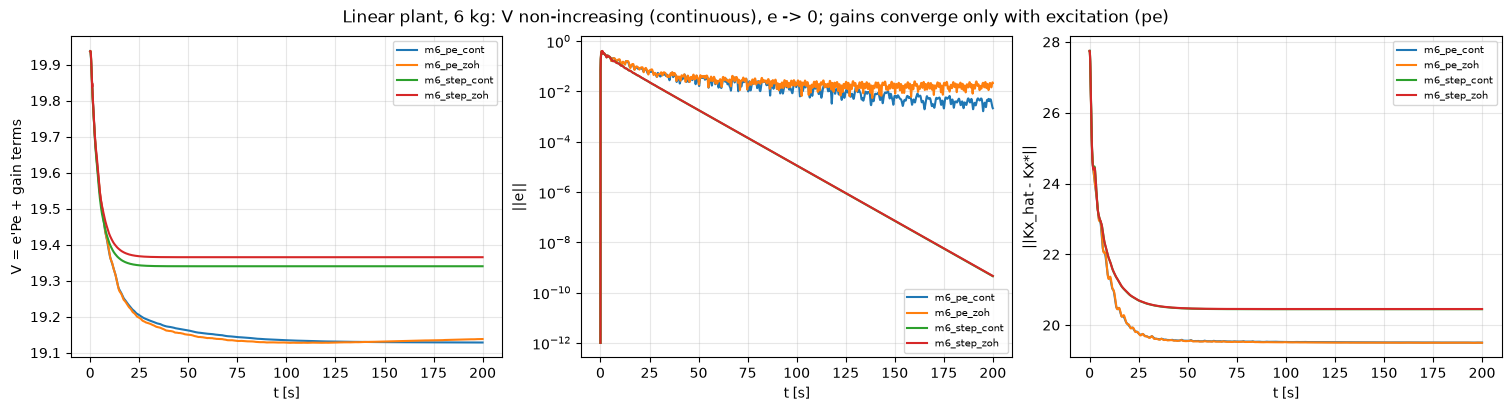

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for f in sorted(VAL.glob("lin_lin_m6_*.npz")):
    z = np.load(f); lab = f.stem.replace("lin_lin_", "")
    ax[0].plot(z["t"], z["V"], label=lab); ax[1].semilogy(z["t"], z["norm_e"] + 1e-12, label=lab)
    ax[2].plot(z["t"], np.linalg.norm(z["Kx"] - z["ideal_Kx"], axis=(1, 2)), label=lab)
ax[0].set_ylabel("V = e'Pe + gain terms"); ax[1].set_ylabel("||e||"); ax[2].set_ylabel("||Kx_hat - Kx*||")
for a in ax: a.set_xlabel("t [s]"); a.grid(alpha=.3); a.legend(fontsize=7)
fig.suptitle("Linear plant, 6 kg: V non-increasing (continuous), e -> 0; gains converge only with excitation (pe)");

### 7.2 Reduced nonlinear plant: ONLINE vs FROZEN vs direct softer baseline (120 s)

- **Arms:** `online` is the law of Section 4 with adaptation; `frozen` is the same law with the gains held at their nominal start values; `softer` is the baseline PID+FF plus the softer damper, with no adaptive layer.
- **`task_rms_last30`** (m): root mean square (RMS) of the distance $\sqrt{y^2+z^2}$ of the vehicle from the task position over the last 30 s of the horizon, $t\in[T-30,T)$.
- **`swing_rms_10_30`** (rad): RMS of the swing angle $\phi_{code}$ over $t\in[10,30)$ s.
- The second table lists episodes that did not complete.

**Output coordinates:** subsequent tables/plots are code-generated in code coordinates; no numeric outputs are transformed into residual.tex coordinates.


In [7]:
nl = summ[(summ.kind == "nonlinear") & summ.id.str.startswith("nl_")].copy()
nl["cell"] = nl.apply(lambda r: f"m{r.m_L:g}_L{r.L:g}_{r.scenario}", axis=1)
cols = ["task_rms_last30", "ref_err_rms_last30", "swing_rms_10_30", "swing_rms_last30", "mean_z_last30", "sat_frac", "status"]
display(nl.pivot_table(index="cell", columns="arm", values=["task_rms_last30", "swing_rms_10_30"], aggfunc="first").round(4))
display(nl[["id", "status", "stop", "t_end"]].query("status != 'completed'"))

swing_rms_10_30                 task_rms_last30          \
arm                       frozen  online  softer          frozen  online   
cell                                                                       
m2_L1.5_hover             0.0267  0.0071  0.0011          0.2431  0.0004   
m2_L1.5_transfer          0.0267  0.0243  0.0027          0.2431  0.0004   
m2_L2_hover               0.0002  0.0031  0.0017          0.3856  0.0004   
m2_L2_transfer            0.0018  0.0088  0.0040          0.3856  0.0004   
m4_L1.5_hover             0.0044  0.0035  0.0000          0.0190  0.0000   
m4_L1.5_transfer          0.0032  0.0069  0.0004          0.0187  0.0000   
m4_L2.5_hover             0.0003  0.0054  0.0003          0.0000  0.0000   
m4_L2.5_transfer          0.0010  0.0088  0.0018          0.0000  0.0000   
m4_L2_hover               0.0002  0.0002  0.0002          0.0000  0.0000   
m4_L2_transfer            0.0011  0.0011  0.0010          0.0000  0.0000   
m6_L2.5_hover             0.0003  0.0085  0.0001          0.3856  0.0004   
m6_L2.5_transfer          0.0008  0.0140  0.0007          0.3856  0.0004   
m6_L2_hover               0.0002  0.0022  0.0001          0.3856  0.0004   
m6_L2_transfer            0.0008  0.0049  0.0003          0.3856  0.0004   

                         
arm              softer  
cell                     
m2_L1.5_hover       0.0  
m2_L1.5_transfer    0.0  
m2_L2_hover         0.0  
m2_L2_transfer      0.0  
m4_L1.5_hover       0.0  
m4_L1.5_transfer    0.0  
m4_L2.5_hover       0.0  
m4_L2.5_transfer    0.0  
m4_L2_hover         0.0  
m4_L2_transfer      0.0  
m6_L2.5_hover       0.0  
m6_L2.5_transfer    0.0  
m6_L2_hover         0.0  
m6_L2_transfer      0.0

,id,status,stop,t_end


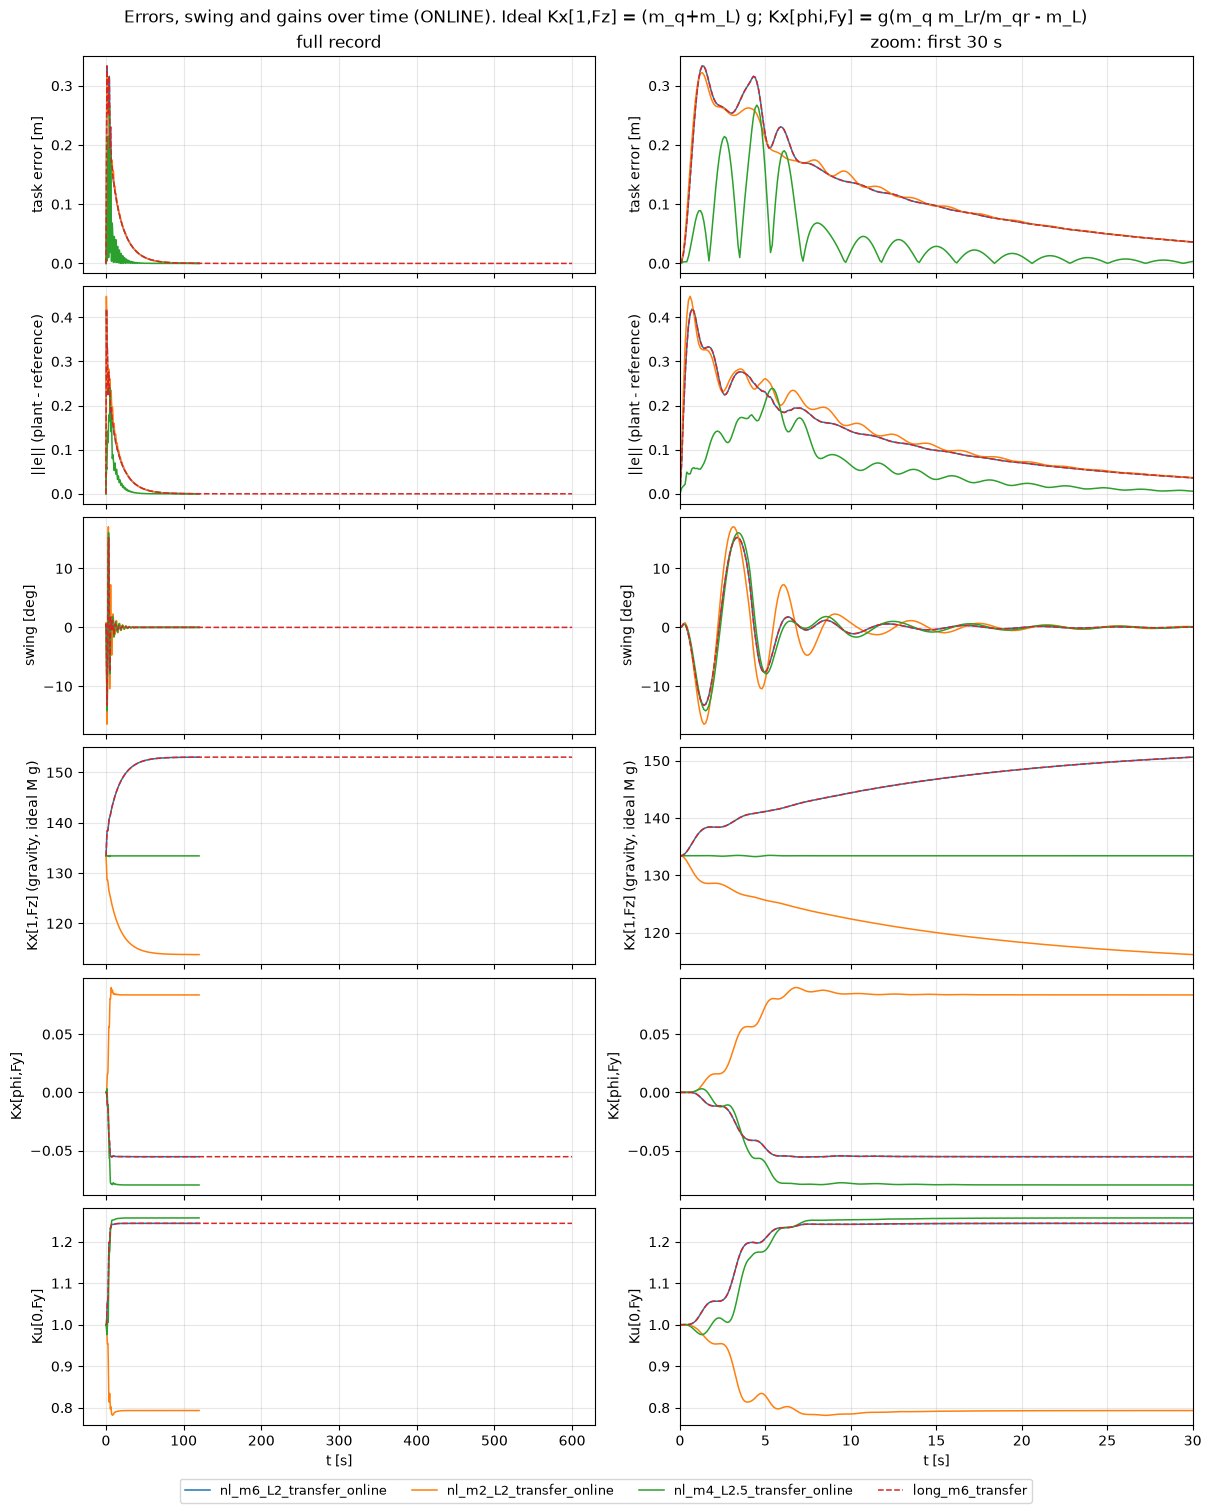

In [8]:
PANELS = [  # (y label, column of the saved episode)
    ("task error [m]", lambda d: np.hypot(d.y, d.z)),
    ("||e|| (plant - reference)", lambda d: d.norm_e),
    ("swing [deg]", lambda d: np.degrees(d.phi)),
    ("Kx[1,Fz] (gravity, ideal M g)", lambda d: d.Kx_one_Fz),
    ("Kx[phi,Fy]", lambda d: d.Kx_phi_Fy),
    ("Ku[0,Fy]", lambda d: d.Ku_0_Fy),
]
ZOOM_S = 30.0  # right column: same arrays, x axis limited to the first ZOOM_S seconds
fig, ax = plt.subplots(len(PANELS), 2, figsize=(12, 15), sharex="col", constrained_layout=True)
for name in ("nl_m6_L2_transfer_online", "nl_m2_L2_transfer_online", "nl_m4_L2.5_transfer_online", "long_m6_transfer"):
    f = VAL / f"{name}.csv"
    if not f.exists():
        continue
    df = pd.read_csv(f)
    ls = "--" if name.startswith("long_") else "-"  # dashed, so the 6 kg trace under it stays visible
    for row, (_, values) in zip(ax, PANELS):
        for a in row:
            a.plot(df.t, values(df), label=name, lw=1.1, ls=ls)
for (full, zoom), (label, _) in zip(ax, PANELS):
    for a in (full, zoom):
        a.set_ylabel(label); a.grid(alpha=.3)
    zoom.set_xlim(0, ZOOM_S)
    inside = np.concatenate([line.get_ydata()[line.get_xdata() <= ZOOM_S] for line in zoom.lines])
    pad = 0.05 * np.ptp(inside)
    zoom.set_ylim(inside.min() - pad, inside.max() + pad)
ax[0, 0].set_title("full record"); ax[0, 1].set_title(f"zoom: first {ZOOM_S:g} s")
for a in ax[-1]: a.set_xlabel("t [s]")
fig.legend(*ax[0, 0].get_legend_handles_labels(), loc="outside lower center", ncols=4, fontsize=9)
fig.suptitle("Errors, swing and gains over time (ONLINE). Ideal Kx[1,Fz] = (m_q+m_L) g; Kx[phi,Fy] = g(m_q m_Lr/m_qr - m_L)");

### 7.3 σ-modification and long horizon

- **Episodes:** `sig_*` are online episodes of 120 s with G0-pre gains plus $\sigma=0.1$ /s; `long_*` are online 600 s transfers with G0-pre gains and no leak.
- **Columns:** `ref_err_rms_last30` is the RMS of the position part of $e$ over the last 30 s, `mean_z_last30` the mean signed vertical task error, and `Kx_one_Fz_*` / `ideal_Kx_one_Fz` the vertical constant gain (last value, standard deviation) and its ideal.
- **Why the leak permits an offset.** Each tick updates $\hat K_{ij}^+=\hat K_{ij}-T_s\Gamma_{ij}\bar x_i(e^\top PB_r)_j-T_s\sigma(\hat K_{ij}-K_{0,ij})$ (box clip inactive). At a steady state $\hat K^+=\hat K$, so $\Gamma_{ij}\bar x_i(e^\top PB_r)_j=-\sigma(\hat K_{ij}-K_{0,ij})$. For the vertical constant entry ($\bar x=1$, $\Gamma=500$) this reads $(e^\top PB_r)_z=-\sigma(\hat K-K_0)/500$: a gain resting away from $K_0$ needs $e\ne0$. At 4 kg the ideal equals $K_0$ (133.416), so $e=0$ is compatible; at 2 and 6 kg it does not equal $K_0$. This is a fixed-point condition; it does not give the size of the offset.

**Output coordinates:** subsequent tables/plots are code-generated in code coordinates; no numeric outputs are transformed into residual.tex coordinates.


In [9]:
sig = summ[summ.id.str.startswith("sig_") | summ.id.str.startswith("long_")]
display(sig[["id", "status", "t_end", "task_rms_last30", "ref_err_rms_last30", "mean_z_last30", "Kx_one_Fz_last", "ideal_Kx_one_Fz", "Kx_one_Fz_std_last30"]].round(4))

,id,status,t_end,task_rms_last30,ref_err_rms_last30,mean_z_last30,Kx_one_Fz_last,ideal_Kx_one_Fz,Kx_one_Fz_std_last30
15,sig_m2_L2_hover,completed,119.9,0.1810,0.1810,0.1810,124.5237,113.796,0.0001
20,sig_m2_L2_transfer,completed,119.9,0.1810,0.1810,0.1810,124.5237,113.796,0.0001
23,sig_m4_L2_hover,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000
28,sig_m4_L2_transfer,completed,119.9,0.0000,0.0000,-0.0000,133.4160,133.416,0.0000
31,sig_m6_L2_hover,completed,119.9,0.1810,0.1810,-0.1810,142.3083,153.036,0.0001
36,sig_m6_L2_transfer,completed,119.9,0.1810,0.1810,-0.1810,142.3083,153.036,0.0001
40,sig_m4_L1.5_hover,completed,119.9,0.0000,0.0000,-0.0000,133.4160,133.416,0.0000
43,sig_m4_L1.5_transfer,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000
48,sig_m4_L2.5_hover,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000
52,sig_m4_L2.5_transfer,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000


### 7.4 Disturbances: none / constant / OU / periodic gust / drag in a steady wind, with and without RBF weights (6 kg / 2 m transfer)

Each disturbance is run independently, with the no-disturbance case as control. `rbf` uses 15 Gaussian RBFs on vehicle velocity with $\sigma_W=0$; `rbfs` uses $\sigma_W=0.1$. The constant regressor entry already estimates constant forces.

- **Disturbances** act on the plant only (force on the vehicle in N, moment in N m); the law never reads them. `none`; `const`: $(F_y,F_z,\tau)=(5,-3,0.5)$; `ou`: an Ornstein-Uhlenbeck (mean-reverting random) process with that mean, standard deviations $(2,1,0.2)$, time constant 3 s and seeds 1 to 3, held over each tick; `gust`: $F_y=3+4\sin(2\pi t/8)$, $F_z=-2\sin(2\pi t/5)$, $\tau=0.3\sin(2\pi t/6)$; `drag`: $0.3\,\|v_w-v\|\,(v_w-v)$ for a steady wind $v_w=(4,0)$ m/s and vehicle velocity $v$.
- **Table arms:** `V0` is G0-pre with adaptation on; `frozen` holds the nominal gains; `rbf` and `rbfs` add $\hat W^\top\Phi_d(v)$ to the force.
- **Metrics:** `task_rms_last30` as in 7.2, and `mean_y_last30`, the mean signed lateral task error over the last 30 s (m).

**Output coordinates:** subsequent tables/plots are code-generated in code coordinates; no numeric outputs are transformed into residual.tex coordinates.


In [10]:
dist = summ[summ.id.str.startswith("dist_")].copy()
dist["wind"] = dist.id.str.extract(r"dist_([a-z]+)\d")
dist["arm2"] = dist.id.str.split("_").str[-1]
display(dist.pivot_table(index=["wind", "seed"], columns="arm2", values="task_rms_last30").round(4))
display(dist.pivot_table(index=["wind", "seed"], columns="arm2", values="mean_y_last30").round(4))

arm2            V0  frozen     rbf    rbfs
wind  seed                                
const 0.0   0.0006  0.5238  0.0001  0.0015
drag  0.0   0.0004  0.5250  0.0001  0.0011
gust  0.0   0.1008  0.5251  0.0874  0.0859
none  0.0   0.0004  0.3856  0.0001  0.0012
ou    1.0   0.0464  0.5359  0.0414  0.0417
      2.0   0.0481  0.4892  0.0394  0.0399
      3.0   0.0436  0.4881  0.0374  0.0368

arm2            V0  frozen     rbf    rbfs
wind  seed                                
const 0.0   0.0000  0.2779  0.0000  0.0001
drag  0.0   0.0000  0.3586  0.0000  0.0001
gust  0.0   0.0009  0.2353 -0.0029 -0.0026
none  0.0  -0.0000 -0.0000 -0.0000 -0.0000
ou    1.0   0.0034  0.2610  0.0032  0.0031
      2.0  -0.0106  0.2193 -0.0090 -0.0095
      3.0  -0.0053  0.1767 -0.0042 -0.0050

## 8. Tuning (protocols 03 and 06)

Tuning followed two pre-registered protocols (documents `03_tuning_protocol_vanilla.md` and `06_t1prime_protocol.md` in the thesis repository's local, untracked `.ai/work/2026-11-25-mrac-vanilla/` folder). **T1** is the tuning stage: 54 candidate gain designs are scored on a grid of mismatched conditions. **T2** is the held-out test of the selected design on conditions not used for the selection. **G3** is the swing gate (the swing RMS over 10 to 30 s must not exceed a bound built from the baselines, `B_S`). **G0-pre** is the pre-tuning default-gain vanilla design, used as the comparison (see the design names in Section 7). (Do not confuse it with **TUNED'-online**, the arm of protocol 08 in NB11 to NB13: that arm is the TUNED' design of protocol 06 with adaptation on.)

**T1 / T2 (protocol 03).** The swing gate G3 (half the softer law's benefit) was about 0.02 deg at 6 kg. It rejected every fast adapter, so the slowest design was selected. On T2 that design was **not good enough**, and G0-pre beat it in 17 of 21 cells.

**T1' / T2' (protocol 06, chosen by Javier).**
- G3' = `max(B_S, 0.005 rad)`. The floor was set after T1 was seen, so T1' is a re-analysis of the same deterministic episodes.
- T2' is a fresh held-out test with 4 never-seen conditions. It ran as two parts (wall cap), combined under amendment AM7 of the protocol (the recorded rule for merging the two parts).
- **Result:** TUNED' tracks at about 1e-5 m and beats G0-pre in 30 cells. All 12 never-seen cells pass G1 and G2.
- **Strict "good enough": NO.** Three cells fail it: two light-load fast transfers that leave the taut-cable domain for every controller, and the 2 kg / 1.5 m short-rope case (saturation and swing).
- Javier accepted TUNED' with these as declared domain limits on 2026-11-25 (approval record of protocol 08; the options are in report `07_t1prime_t2prime_report.md`; both local, untracked). (An earlier text said that this decision was open.)

In [11]:
_results.require('mrac_vanilla_tune_20261125T024907', results=RES)
T1 = RES / "mrac_vanilla_tune_20261125T024907"
for name in ("analysis", "analysis_t1prime"):
    an = json.loads((T1 / f"{name}.json").read_text())
    print(f"{name}: floor {an.get('g3_floor_rad', 0.0)} | pass {an['n_pass']}/{an['n_designs']} | gate failures {an['fail_counts']} | selected {an['selected']['tag']} ({an['selected']['mean_task_rms_last30']:.2e} m)")
an = json.loads((T1 / "analysis_t1prime.json").read_text())
display(pd.DataFrame([dict(tag=d["tag"], passes=d["pass"], mean_task_rms_last30=d["mean_task_rms_last30"],
                           G3_failed_cells=", ".join(d["G3_cells_failed"])) for d in an["all_designs"]]).head(15))

analysis: floor 0.0 | pass 6/54 | gate failures {'G1': 0, 'G2': 0, 'G3': 48} | selected gs5_gc200_cy0.25_gu0.3_s0 (2.19e-02 m)
analysis_t1prime: floor 0.005 | pass 42/54 | gate failures {'G1': 0, 'G2': 0, 'G3': 12} | selected gs5_gc1000_cy0.25_gu0.3_s0 (1.87e-05 m)


,tag,passes,mean_task_rms_last30,G3_failed_cells
0,gs5_gc1000_cy0.25_gu0.3_s0,True,0.000019,
1,gs20_gc1000_cy0.25_gu0.3_s0,True,0.000019,
2,gs80_gc1000_cy0.25_gu0.3_s0,True,0.000019,
3,gs5_gc1000_cy0.25_gu1_s0,True,0.000035,
4,gs20_gc1000_cy0.25_gu1_s0,True,0.000035,
5,gs80_gc1000_cy0.25_gu1_s0,True,0.000036,
6,gs5_gc1000_cy0.25_gu3_s0,True,0.000108,
7,gs20_gc1000_cy0.25_gu3_s0,True,0.000108,
8,gs80_gc1000_cy0.25_gu3_s0,True,0.000108,
9,gs80_gc1000_cy1_gu3_s0,False,0.000363,"m2_L2_q1_hover, m2_L2_q1_transfer, m6_L2_q1_ho..."


In [12]:
_results.require('mrac_vanilla_tune_20261125T024907', 'mrac_vanilla_heldout_20261125T034506', 'mrac_vanilla_heldout_composite_20261125T111150', results=RES)
for label, folder, name in (("T2 (protocol 03)", "mrac_vanilla_heldout_20261125T034506", "analysis"),
                            ("T2' (protocol 06, composite)", "mrac_vanilla_heldout_composite_20261125T111150", "analysis_t2prime")):
    ah = json.loads((RES / folder / f"{name}.json").read_text())
    print(f"== {label}: good_enough={ah['good_enough']} | crit2 {ah['criterion2_adaptation_benefit']} | crit3 {ah['criterion3_swing']} | regressions vs V0 {ah['regressions_vs_v0']} | V0 beats tuned in {len(ah['v0_beats_tuned'])} cells")
ah = json.loads((RES / "mrac_vanilla_heldout_composite_20261125T111150" / "analysis_t2prime.json").read_text())
cells = pd.DataFrame(ah["cells"])
cells["unseen"] = cells.cell.str.startswith(("m3_L2_", "m5_L2_", "m4_L1.75_", "m4_L2_q0.85"))
display(cells[["cell", "unseen", "matched", "G1", "G2", "G3", "tuned_online_task", "tuned_frozen_task", "v0_online_task",
               "tuned_swing_10_30", "B_S", "tuned_status"]].round(5))

== T2 (protocol 03): good_enough=False | crit2 8/8 matched cells with both arms completed (9 matched cells in total) | crit3 16/19 evaluable (2 not evaluable: a baseline failed, AM5) | regressions vs V0 ['m2.5_L2_q1_transfer_fast'] | V0 beats tuned in 17 cells
== T2' (protocol 06, composite): good_enough=False | crit2 17/17 matched cells with both arms completed (18 matched cells in total) | crit3 27/30 evaluable (3 not evaluable: a baseline failed, AM5) | regressions vs V0 ['m2.5_L2_q1_transfer_fast'] | V0 beats tuned in 1 cells


,cell,unseen,matched,G1,G2,G3,tuned_online_task,tuned_frozen_task,v0_online_task,tuned_swing_10_30,B_S,tuned_status
0,m2.5_L2_q1_hover,False,True,True,True,True,0.00000,0.28921,0.00018,0.00041,0.00500,completed
1,m2.5_L2_q1_transfer,False,True,True,True,True,0.00000,0.28921,0.00018,0.00261,0.01170,completed
2,m2.5_L2_q1_transfer_fast,False,True,False,False,None,NaN,NaN,0.00013,NaN,NaN,failed
3,m2_L1.5_q1_hover,False,False,False,True,False,0.00003,0.24305,0.00040,0.02048,0.00500,completed
4,m2_L1.5_q1_transfer,False,False,True,True,False,0.00002,0.24305,0.00040,0.01702,0.00606,completed
5,m2_L1.5_q1_transfer_fast,False,False,False,False,None,NaN,NaN,NaN,NaN,NaN,failed
6,m3_L2_q1_hover,True,True,True,True,True,0.00000,0.19281,0.00007,0.00027,0.00500,completed
7,m3_L2_q1_transfer,True,True,True,True,True,0.00000,0.19281,0.00007,0.00197,0.00902,completed
8,m3_L2_q1_transfer_fast,True,True,True,True,None,0.00000,0.19281,0.00006,0.00221,NaN,completed
9,m4_L1.5_q1_hover,False,False,True,True,True,0.00001,0.01895,0.00000,0.00118,0.00500,completed


## 9. Claim limits and next step

- **Derived conditionally:** for the exactly matched continuous-time linear outer model, under the assumptions stated in Section 4, the adaptive cross terms cancel, $\dot V=-e^TQe\le0$, and Barbalat gives $e\to0$.
- **Not established:** parameter convergence without persistent excitation, or a generic RBF/UUB result for approximation error, wind or the nonlinear remainder.
- **Not proved:** stability or convergence for the nonlinear sampled loop with attitude dynamics, motor lag, saturation or length mismatch. Its episodes are local finite-horizon numerical evidence (PROXY).
- **Code-coordinate outputs:** numerical tables and plots retain the implementation's state and angle convention; no values were converted to residual.tex coordinates.
- **Next:** any further substitution or extension requires Javier's approval; the proof above does not transfer automatically to the sampled or nonlinear system. Combining MRAC with a residual policy is planned for evaluation on the Pymunk plant, with no observation adapter (project master plan, item A6; a local planning document). Offline MRAC with the damper reference remains the theory and tuning vehicle. Nothing of that combination has been run.